In [1]:
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)

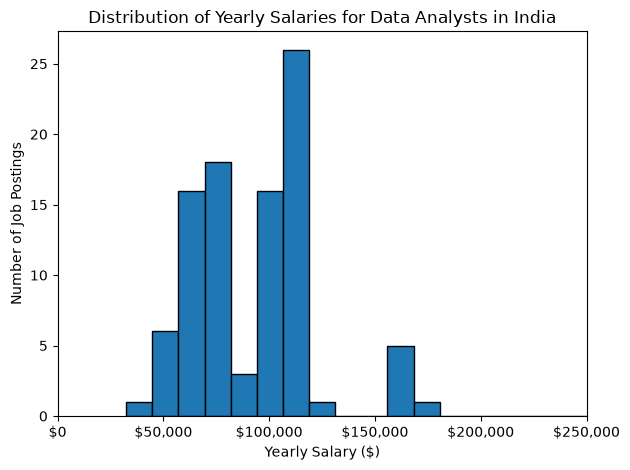

In [22]:
df_DA_IN = df[
    (df['job_country'] == 'India') &
    (df['job_title_short'] == 'Data Analyst')
].copy()

df_DA_IN['salary_year_avg'].plot(
    kind='hist',
    bins=50,
    edgecolor='black'
)

ax = plt.gca()

# Format x-axis salaries with a dollar sign
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x:,.0f}')
)

plt.xlim(0, 250000)

plt.xlabel('Yearly Salary ($)')
plt.ylabel('Number of Job Postings')
plt.title('Distribution of Yearly Salaries for Data Analysts in India')

plt.tight_layout()
plt.show()